# COMS4060A/7056A Assignment 2: NYC Taxi Trips

This notebook covers Question 1 (Data Cleaning), Question 2 (Feature Generation) and Question 3 (Time-based analysis).
Every figure is saved as a PNG in the current directory, named after the question it belongs to
(for example `q3_1_trips_by_weekday.png`), so that it can be included in the LaTeX report.

The notebook expects `train.csv` (the Kaggle training file) in the same folder.

In [2]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import warnings
warnings.filterwarnings("ignore")

BLUE, ORANGE, GREY, INK = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#2a78d6", "#0d366b"])

mpl.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "figure.dpi": 110, "savefig.dpi": 200,
    "savefig.bbox": "tight", "font.size": 10, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "text.color": INK,
})

DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]


def save(fig, name):
    fig.savefig(name)
    plt.show()
    print("saved", name)


def haversine_np(lon1, lat1, lon2, lat2):
    # Great circle distance in km between points given in decimal degrees (from the assignment brief).
    lon1, lat1, lon2, lat2 = map(np.radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = np.sin(dlat / 2.0) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2.0) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return 6367 * c

# Question 1: Data Cleaning

In [3]:
df = pd.read_csv("train.csv", parse_dates=["pickup_datetime", "dropoff_datetime"])
print("shape:", df.shape)
display(df.head())
print(df.dtypes)
print("missing values:", int(df.isna().sum().sum()))
print("duplicate ids:", int(df.id.duplicated().sum()))
dur_check = (df.dropoff_datetime - df.pickup_datetime).dt.total_seconds()
print("rows where trip_duration differs from dropoff minus pickup:", int((dur_check != df.trip_duration).sum()))
print("pickup range:", df.pickup_datetime.min(), "to", df.pickup_datetime.max())

shape: (1458644, 11)


,id,vendor_id,pickup_datetime,dropoff_datetime,passenger_count,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,store_and_fwd_flag,trip_duration
0,id2875421,2,2016-03-14 17:24:55,2016-03-14 17:32:30,1,-73.982155,40.767937,-73.964630,40.765602,N,455
1,id2377394,1,2016-06-12 00:43:35,2016-06-12 00:54:38,1,-73.980415,40.738564,-73.999481,40.731152,N,663
2,id3858529,2,2016-01-19 11:35:24,2016-01-19 12:10:48,1,-73.979027,40.763939,-74.005333,40.710087,N,2124
3,id3504673,2,2016-04-06 19:32:31,2016-04-06 19:39:40,1,-74.010040,40.719971,-74.012268,40.706718,N,429
4,id2181028,2,2016-03-26 13:30:55,2016-03-26 13:38:10,1,-73.973053,40.793209,-73.972923,40.782520,N,435


id                               str
vendor_id                      int64
pickup_datetime       datetime64[us]
dropoff_datetime      datetime64[us]
passenger_count                int64
pickup_longitude             float64
pickup_latitude              float64
dropoff_longitude            float64
dropoff_latitude             float64
store_and_fwd_flag               str
trip_duration                  int64
dtype: object
missing values: 0
duplicate ids: 0
rows where trip_duration differs from dropoff minus pickup: 0
pickup range: 2016-01-01 00:00:17 to 2016-06-30 23:59:39


Distance and speed are needed to find outliers, so we compute them first (Question 2 allows feature generation before or after cleaning).
Distance is the straight line (haversine) distance between pickup and dropoff, so it is a lower bound on the real road distance.

In [4]:
df["distance_km"] = haversine_np(df.pickup_longitude, df.pickup_latitude,
                                 df.dropoff_longitude, df.dropoff_latitude)
df["avg_speed_kmh"] = df.distance_km / (df.trip_duration / 3600)

raw = df[["trip_duration", "distance_km", "avg_speed_kmh", "passenger_count"]]
display(raw.describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).T)
print("passenger_count values:")
print(df.passenger_count.value_counts().sort_index())

,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
trip_duration,1458644.0,959.492273,5237.431724,1.0,7.0,87.000000,662.000000,3440.000000,85128.357000,3.526282e+06
distance_km,1458644.0,3.438704,4.293840,0.0,0.0,0.138935,2.092403,20.774468,24.751208,1.240130e+03
avg_speed_kmh,1458644.0,14.414153,14.968121,0.0,0.0,1.393366,12.783947,40.719722,54.267879,9.269014e+03
passenger_count,1458644.0,1.664530,1.314242,0.0,1.0,1.000000,1.000000,6.000000,6.000000,9.000000e+00


passenger_count values:
passenger_count
0         60
1    1033540
2     210318
3      59896
4      28404
5      78088
6      48333
7          3
8          1
9          1
Name: count, dtype: int64


## Outlier rules

Each rule below has a physical or practical reason, and the table after it shows how many trips each rule flags.

| Rule | Reason |
|---|---|
| Pickup or dropoff outside the NYC area (lon -74.3 to -73.65, lat 40.45 to 41.0) | The data is for NYC taxis. Points in other states, the ocean or at (0, 0) are GPS errors. The box still contains JFK, LaGuardia and Newark. |
| Passenger count 0 or above 6 | A taxi with no passenger is not a fare, and vehicles used as taxis seat at most 6 people, so counts of 7 to 9 are entry errors (the count is typed in by the driver). |
| Duration under 60 s | Too short for a real fare. Mostly cancelled rides or a meter switched on by mistake. |
| Duration over 3 hours | Almost no legitimate trip inside NYC takes this long. There is a clear spike of trips close to 24 hours, which is a meter left running. |
| Distance under 50 m | The pickup and dropoff are at the same place, so the speed is meaningless. These are cancelled trips. |
| Speed over 100 km/h | The speed is measured in a straight line, so real speed is even higher. This is faster than the fastest legal road speed around NYC. |
| Speed under 1 km/h | Slower than walking, so the car effectively did not move for the whole trip. |

In [5]:
LON_MIN, LON_MAX, LAT_MIN, LAT_MAX = -74.3, -73.65, 40.45, 41.0
MIN_DUR, MAX_DUR = 60, 3 * 3600
MIN_DIST = 0.05
MIN_SPEED, MAX_SPEED = 1, 100

inside = (df.pickup_longitude.between(LON_MIN, LON_MAX) & df.pickup_latitude.between(LAT_MIN, LAT_MAX) &
          df.dropoff_longitude.between(LON_MIN, LON_MAX) & df.dropoff_latitude.between(LAT_MIN, LAT_MAX))

rules = {
    "Pickup or dropoff outside NYC area": ~inside,
    "Passenger count 0 or above 6": ~df.passenger_count.between(1, 6),
    "Duration under 60 s": df.trip_duration < MIN_DUR,
    "Duration over 3 hours": df.trip_duration > MAX_DUR,
    "Distance under 50 m": df.distance_km < MIN_DIST,
    "Speed over 100 km/h": df.avg_speed_kmh > MAX_SPEED,
    "Speed under 1 km/h": df.avg_speed_kmh < MIN_SPEED,
}

keep = pd.Series(True, index=df.index)
rows = []
for name, mask in rules.items():
    newly = int((mask & keep).sum())
    keep &= ~mask
    rows.append({"rule": name, "flagged_alone": int(mask.sum()), "newly_removed": newly,
                 "cumulative_removed": int((~keep).sum())})
removal = pd.DataFrame(rows)
removal["flagged_alone_%"] = (removal.flagged_alone / len(df) * 100).round(3)
removal["newly_removed_%"] = (removal.newly_removed / len(df) * 100).round(3)
display(removal)

df_raw = df
df = df_raw[keep].copy()
print("rows before:", len(df_raw), " rows after:", len(df),
      " removed:", len(df_raw) - len(df), f"({(1 - len(df) / len(df_raw)) * 100:.2f}%)")
display(df[["trip_duration", "distance_km", "avg_speed_kmh", "passenger_count"]]
        .describe(percentiles=[0.001, 0.01, 0.5, 0.99, 0.999]).T)

,rule,flagged_alone,newly_removed,cumulative_removed,flagged_alone_%,newly_removed_%
0,Pickup or dropoff outside NYC area,773,773,773,0.053,0.053
1,Passenger count 0 or above 6,65,64,837,0.004,0.004
2,Duration under 60 s,8595,8434,9271,0.589,0.578
3,Duration over 3 hours,2112,2105,11376,0.145,0.144
4,Distance under 50 m,11333,6155,17531,0.777,0.422
5,Speed over 100 km/h,175,33,17564,0.012,0.002
6,Speed under 1 km/h,13241,2050,19614,0.908,0.141


rows before: 1458644  rows after: 1439030  removed: 19614 (1.34%)


,count,mean,std,min,0.1%,1%,50%,99%,99.9%,max
trip_duration,1439030.0,840.451272,653.528781,60.000000,69.000000,111.000000,665.000000,3303.000000,5046.000000,10731.00000
distance_km,1439030.0,3.459864,3.889074,0.050192,0.153794,0.382198,2.116495,20.743383,23.706265,47.73514
avg_speed_kmh,1439030.0,14.466055,7.596428,1.000377,1.539719,3.313453,12.850014,40.374586,52.431961,99.46905
passenger_count,1439030.0,1.665054,1.314261,1.000000,1.000000,1.000000,1.000000,6.000000,6.000000,6.00000


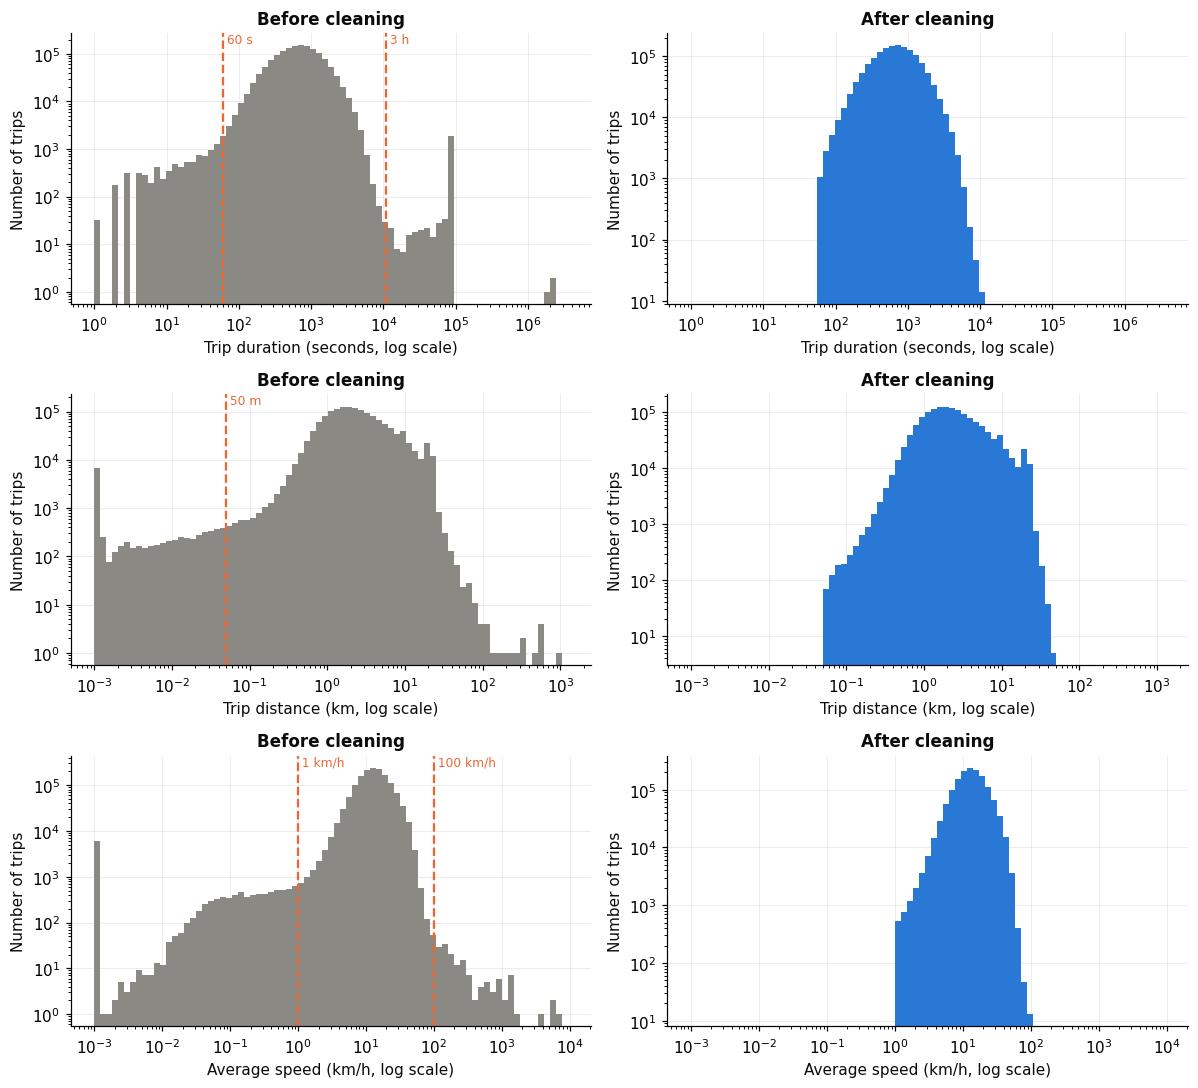

saved q1_outliers_before_after.png


In [6]:
def logbins(x, n=80):
    x = x[x > 0]
    return np.logspace(np.log10(x.min()), np.log10(x.max()), n)

fig, axes = plt.subplots(3, 2, figsize=(11, 10))
specs = [
    ("trip_duration", "Trip duration (seconds, log scale)", [(MIN_DUR, "60 s"), (MAX_DUR, "3 h")]),
    ("distance_km", "Trip distance (km, log scale)", [(MIN_DIST, "50 m")]),
    ("avg_speed_kmh", "Average speed (km/h, log scale)", [(MIN_SPEED, "1 km/h"), (MAX_SPEED, "100 km/h")]),
]
for i, (col, label, lines) in enumerate(specs):
    bins = logbins(df_raw[col].clip(lower=1e-3))
    for j, (data, title, colour) in enumerate([(df_raw, "Before cleaning", GREY), (df, "After cleaning", BLUE)]):
        ax = axes[i, j]
        ax.hist(data[col].clip(lower=1e-3), bins=bins, color=colour)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel(label)
        ax.set_ylabel("Number of trips")
        ax.set_title(title)
        if j == 0:
            for v, t in lines:
                ax.axvline(v, color=ORANGE, lw=1.5, ls="--")
                ax.text(v, ax.get_ylim()[1], " " + t, color=ORANGE, va="top", ha="left", fontsize=8)
fig.tight_layout()
save(fig, "q1_outliers_before_after.png")

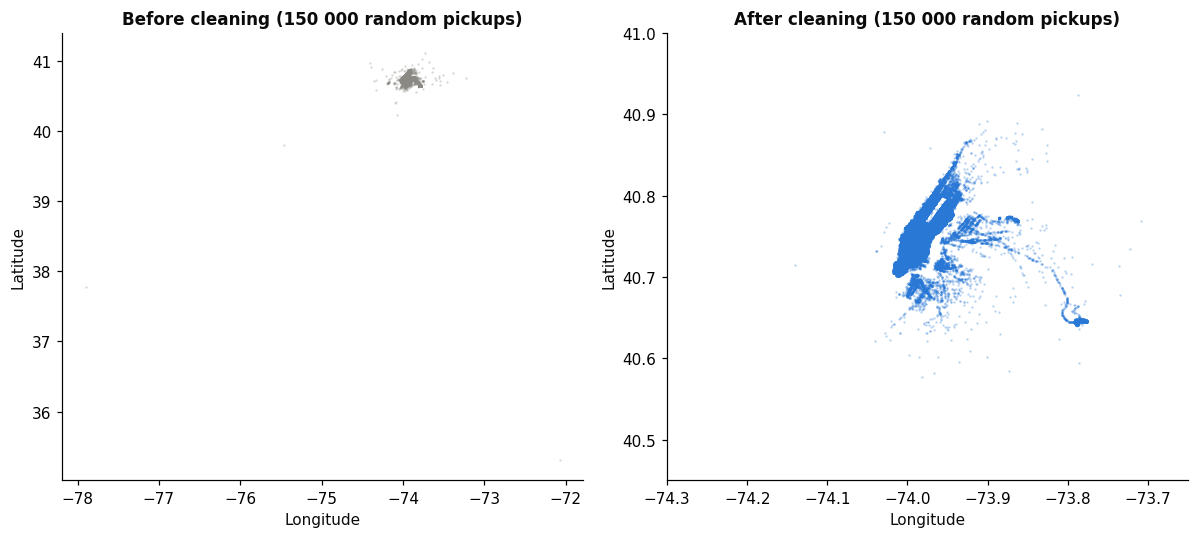

saved q1_pickup_coordinates_before_after.png


In [7]:
samp_raw = df_raw.sample(150000, random_state=42)
samp_clean = df.sample(150000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, data, title, colour in [(axes[0], samp_raw, "Before cleaning", GREY), (axes[1], samp_clean, "After cleaning", BLUE)]:
    ax.scatter(data.pickup_longitude, data.pickup_latitude, s=0.3, alpha=0.3, color=colour, rasterized=True)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title(title + " (150 000 random pickups)")
    ax.grid(False)
axes[1].set_xlim(LON_MIN, LON_MAX)
axes[1].set_ylim(LAT_MIN, LAT_MAX)
fig.tight_layout()
save(fig, "q1_pickup_coordinates_before_after.png")

# Question 2: Feature Generation

Distance and average speed were already created in Question 1 (they are needed to find outliers).
Here we confirm them on the cleaned data and add the day of week and a few helper columns that the later questions use.

In [8]:
dt = df.pickup_datetime.dt
df["day_of_week"] = dt.day_name()
df["dow"] = dt.dayofweek                 # 0 = Monday, 6 = Sunday
df["is_weekend"] = df.dow >= 5
df["day_type"] = np.where(df.is_weekend, "Weekend", "Weekday")
df["hour"] = dt.hour
df["date"] = dt.normalize()
df["month"] = dt.month
df["duration_min"] = df.trip_duration / 60

# distance_km uses the haversine formula and avg_speed_kmh = distance_km / (trip_duration / 3600)
check = (df.distance_km / (df.trip_duration / 3600) - df.avg_speed_kmh).abs().max()
print("largest difference when recomputing speed:", check)

new_cols = ["pickup_datetime", "trip_duration", "distance_km", "day_of_week", "hour", "is_weekend", "avg_speed_kmh"]
display(df[new_cols].head(8))
display(df[["distance_km", "duration_min", "avg_speed_kmh"]].describe().T)

largest difference when recomputing speed: 0.0


,pickup_datetime,trip_duration,distance_km,day_of_week,hour,is_weekend,avg_speed_kmh
0,2016-03-14 17:24:55,455,1.497580,Monday,17,False,11.848984
1,2016-06-12 00:43:35,663,1.804374,Sunday,0,True,9.797504
2,2016-01-19 11:35:24,2124,6.381090,Tuesday,11,False,10.815406
3,2016-04-06 19:32:31,429,1.484566,Wednesday,19,False,12.457894
4,2016-03-26 13:30:55,435,1.187842,Saturday,13,True,9.830418
5,2016-01-30 22:01:40,443,1.098252,Saturday,22,True,8.924851
6,2016-06-17 22:34:59,341,1.325446,Friday,22,False,13.992977
7,2016-05-21 07:54:58,1551,5.711393,Saturday,7,True,13.256617


,count,mean,std,min,25%,50%,75%,max
distance_km,1439030.0,3.459864,3.889074,0.050192,1.255905,2.116495,3.904652,47.73514
duration_min,1439030.0,14.007521,10.892146,1.000000,6.683333,11.083333,17.916667,178.85000
avg_speed_kmh,1439030.0,14.466055,7.596428,1.000377,9.224819,12.850014,17.870927,99.46905


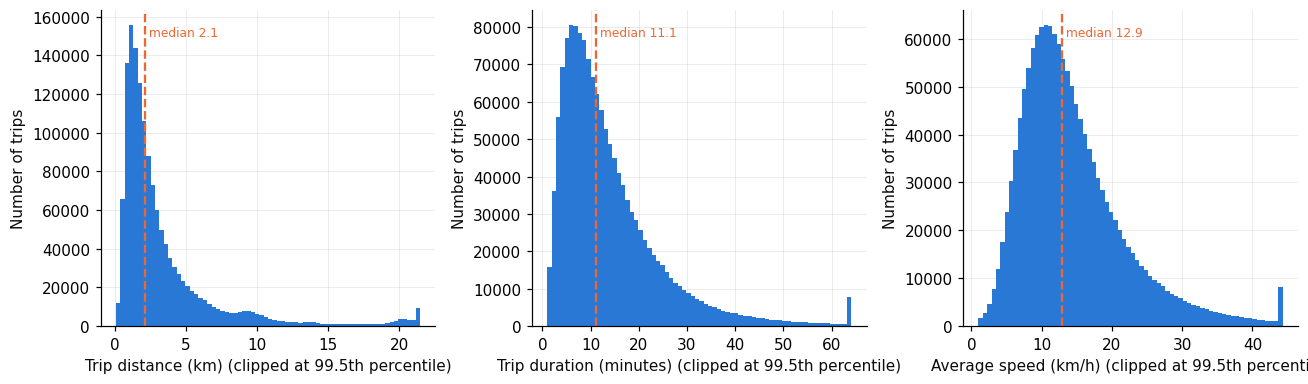

saved q2_feature_distributions.png


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, col, label, hi in [(axes[0], "distance_km", "Trip distance (km)", None),
                           (axes[1], "duration_min", "Trip duration (minutes)", None),
                           (axes[2], "avg_speed_kmh", "Average speed (km/h)", None)]:
    upper = df[col].quantile(0.995)
    ax.hist(df[col].clip(upper=upper), bins=70, color=BLUE)
    ax.axvline(df[col].median(), color=ORANGE, lw=1.5, ls="--")
    ax.text(df[col].median(), ax.get_ylim()[1] * 0.95, f" median {df[col].median():.1f}", color=ORANGE, va="top", fontsize=8)
    ax.set_xlabel(label + " (clipped at 99.5th percentile)")
    ax.set_ylabel("Number of trips")
fig.tight_layout()
save(fig, "q2_feature_distributions.png")

# Question 3: Time-based analysis

Pickup time is used throughout. The data covers 2016-01-01 to 2016-06-30, which is exactly 26 weeks,
so every day of the week occurs exactly 26 times and the totals per day of the week can be compared fairly.

## 3.1 Most popular day of the week

In [10]:
daily = df.groupby("date").size().rename("trips").to_frame()
daily["day_of_week"] = daily.index.day_name()
n_days = daily.groupby("day_of_week").size().reindex(DAYS)
by_day = df.groupby("day_of_week").size().reindex(DAYS)

summary = pd.DataFrame({
    "trips": by_day,
    "share_%": (by_day / by_day.sum() * 100).round(2),
    "days_in_data": n_days,
    "mean_trips_per_day": (by_day / n_days).round(0),
    "median_trips_per_day": daily.groupby("day_of_week").trips.median().reindex(DAYS).round(0),
})
# 23 and 24 January 2016 was a blizzard that shut the city down, so we also look at the days without it
blizzard_days = [pd.Timestamp("2016-01-23"), pd.Timestamp("2016-01-24")]
daily_nb = daily.drop(blizzard_days)
summary["mean_trips_per_day_no_blizzard"] = daily_nb.groupby("day_of_week").trips.mean().reindex(DAYS).round(0)
display(summary)
print("Most popular day by total trips:", by_day.idxmax())
print("Most popular day by median daily trips:", summary.median_trips_per_day.idxmax())
print("Most popular day by mean daily trips without the blizzard days:", summary.mean_trips_per_day_no_blizzard.idxmax())
print()
print("Ten quietest days:")
display(daily.sort_values("trips").head(10))

,trips,share_%,days_in_data,mean_trips_per_day,median_trips_per_day,mean_trips_per_day_no_blizzard
day_of_week,,,,,,
Monday,184917,12.85,26,7112.0,7174.0,7112.0
Tuesday,200072,13.90,26,7695.0,7710.0,7695.0
Wednesday,207492,14.42,26,7980.0,7941.0,7980.0
Thursday,215636,14.98,26,8294.0,8310.0,8294.0
Friday,220506,15.32,26,8481.0,8570.0,8481.0
Saturday,217882,15.14,26,8380.0,8797.0,8651.0
Sunday,192525,13.38,26,7405.0,7640.0,7568.0


Most popular day by total trips: Friday
Most popular day by median daily trips: Saturday
Most popular day by mean daily trips without the blizzard days: Saturday

Ten quietest days:


,trips,day_of_week
date,,
2016-01-23,1615,Saturday
2016-01-24,3322,Sunday
2016-05-30,5491,Monday
2016-01-25,5976,Monday
2016-01-03,6241,Sunday
2016-05-29,6281,Sunday
2016-01-02,6424,Saturday
2016-01-04,6614,Monday
2016-06-20,6806,Monday


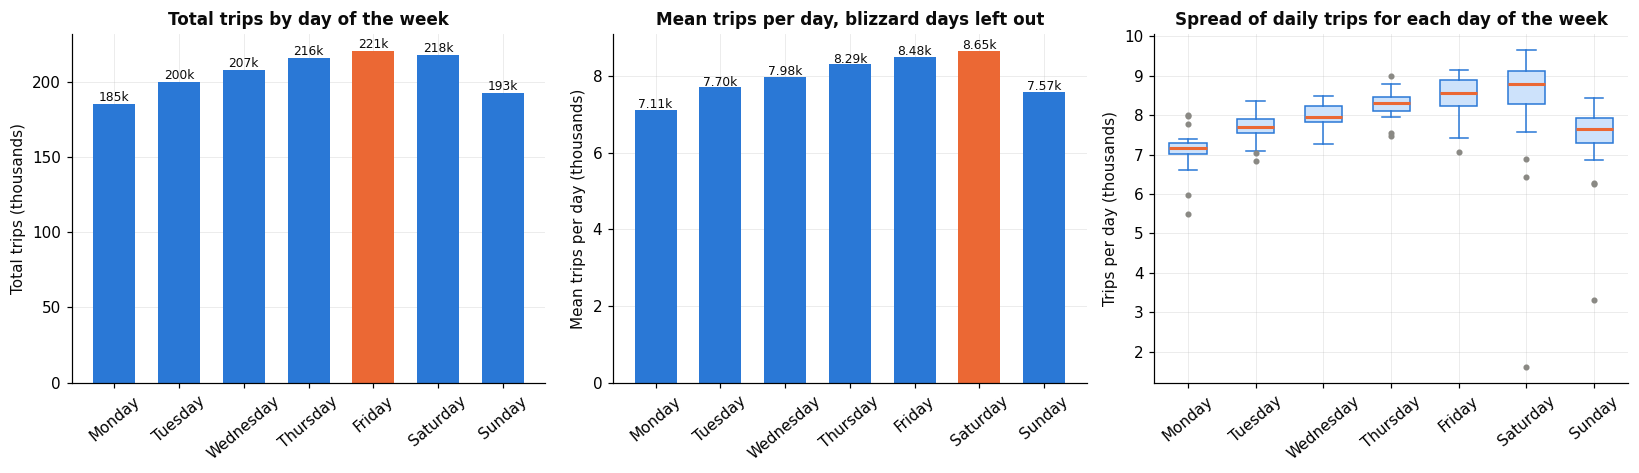

saved q3_1_trips_by_weekday.png


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
ax = axes[0]
colours = [ORANGE if d == by_day.idxmax() else BLUE for d in DAYS]
ax.bar(DAYS, by_day / 1000, color=colours, width=0.65)
for i, v in enumerate(by_day / 1000):
    ax.text(i, v + 2, f"{v:.0f}k", ha="center", fontsize=8)
ax.set_ylabel("Total trips (thousands)")
ax.set_title("Total trips by day of the week")
ax.tick_params(axis="x", rotation=40)

ax = axes[1]
m = summary.mean_trips_per_day_no_blizzard
colours = [ORANGE if d == m.idxmax() else BLUE for d in DAYS]
ax.bar(DAYS, m / 1000, color=colours, width=0.65)
for i, v in enumerate(m / 1000):
    ax.text(i, v + 0.05, f"{v:.2f}k", ha="center", fontsize=8)
ax.set_ylabel("Mean trips per day (thousands)")
ax.set_title("Mean trips per day, blizzard days left out")
ax.tick_params(axis="x", rotation=40)

ax = axes[2]
data = [daily[daily.day_of_week == d].trips.values / 1000 for d in DAYS]
ax.boxplot(data, tick_labels=DAYS, widths=0.55, patch_artist=True, showfliers=True,
           boxprops=dict(facecolor="#cde2fb", edgecolor=BLUE), medianprops=dict(color=ORANGE, lw=2),
           whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE),
           flierprops=dict(marker="o", markersize=3, markerfacecolor=GREY, markeredgecolor=GREY))
ax.set_ylabel("Trips per day (thousands)")
ax.set_title("Spread of daily trips for each day of the week")
ax.tick_params(axis="x", rotation=40)
fig.tight_layout()
save(fig, "q3_1_trips_by_weekday.png")

## 3.2 Most popular hour on each day

In [12]:
hourly = df.groupby(["day_of_week", "hour"]).size().unstack("hour").reindex(DAYS)
peak = pd.DataFrame({
    "peak_hour": hourly.idxmax(axis=1),
    "trips_at_peak": hourly.max(axis=1),
    "quietest_hour": hourly.idxmin(axis=1),
    "trips_at_quietest": hourly.min(axis=1),
})
display(peak)
overall_hour = df.groupby("hour").size()
print("Overall peak hour:", overall_hour.idxmax(), " overall quietest hour:", overall_hour.idxmin())
print()
print("Share of trips between 18:00 and 19:59 on each day (%):")
print((hourly.loc[:, 18:19].sum(axis=1) / hourly.sum(axis=1) * 100).round(1))

,peak_hour,trips_at_peak,quietest_hour,trips_at_quietest
day_of_week,,,,
Monday,18,12812,3,1204
Tuesday,18,13315,3,989
Wednesday,19,13549,4,1223
Thursday,21,13986,4,1348
Friday,19,13998,4,2261
Saturday,23,13030,5,1954
Sunday,0,12116,5,1912


Overall peak hour: 18  overall quietest hour: 5

Share of trips between 18:00 and 19:59 on each day (%):
day_of_week
Monday       13.5
Tuesday      13.1
Wednesday    12.8
Thursday     12.7
Friday       12.4
Saturday     11.8
Sunday       10.9
dtype: float64


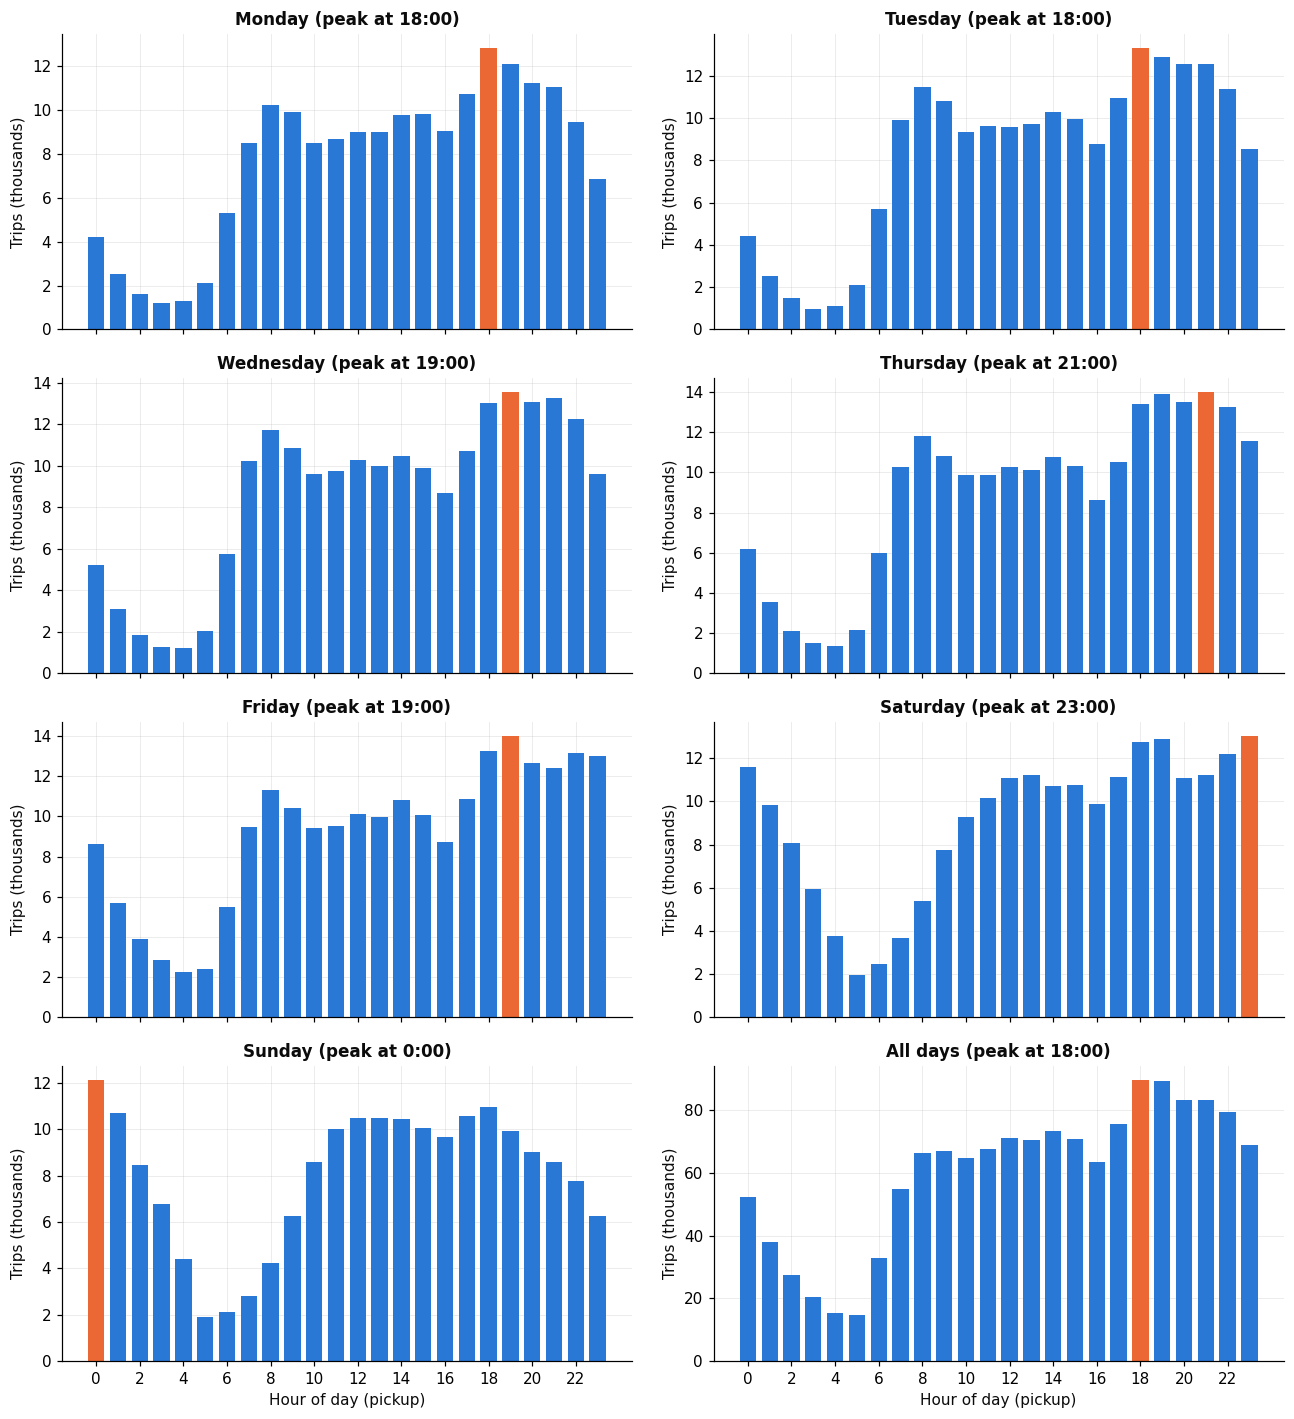

saved q3_2_hourly_by_day.png


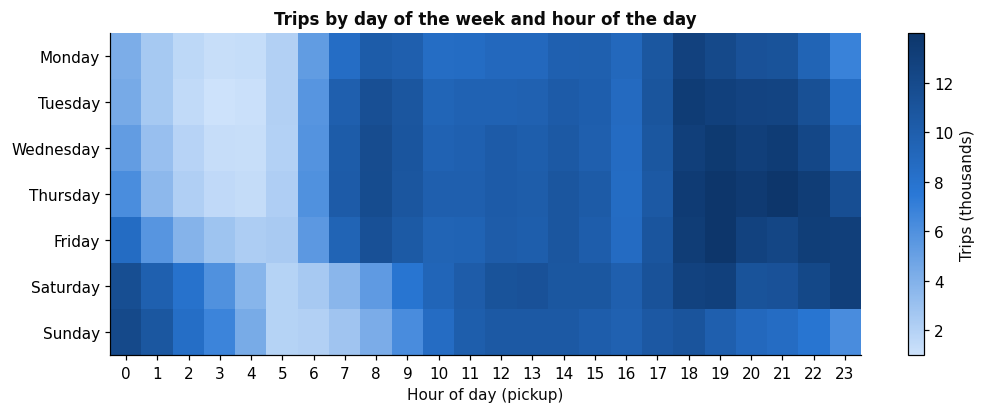

saved q3_2_heatmap_day_hour.png


In [13]:
fig, axes = plt.subplots(4, 2, figsize=(12, 13), sharex=True)
panels = DAYS + ["All days"]
for ax, name in zip(axes.ravel(), panels):
    vals = (overall_hour if name == "All days" else hourly.loc[name]) / 1000
    colours = [ORANGE if h == vals.idxmax() else BLUE for h in vals.index]
    ax.bar(vals.index, vals.values, color=colours, width=0.75)
    ax.set_title(f"{name} (peak at {vals.idxmax()}:00)")
    ax.set_ylabel("Trips (thousands)")
for ax in axes[-1]:
    ax.set_xlabel("Hour of day (pickup)")
    ax.set_xticks(range(0, 24, 2))
fig.tight_layout()
save(fig, "q3_2_hourly_by_day.png")

fig, ax = plt.subplots(figsize=(11, 3.8))
M = hourly.values / 1000
im = ax.imshow(M, aspect="auto", cmap=SEQ)
ax.set_xticks(range(24))
ax.set_yticks(range(7))
ax.set_yticklabels(DAYS)
ax.set_xlabel("Hour of day (pickup)")
ax.grid(False)
cb = fig.colorbar(im, ax=ax)
cb.set_label("Trips (thousands)")
ax.set_title("Trips by day of the week and hour of the day")
save(fig, "q3_2_heatmap_day_hour.png")

## 3.3 Weekdays versus weekends

In [14]:
days_per_type = daily.assign(day_type=np.where(daily.index.dayofweek >= 5, "Weekend", "Weekday")).groupby("day_type").size()
trips_per_type = df.groupby("day_type").size()
print("days in data:", days_per_type.to_dict())
print("mean trips per day:", (trips_per_type / days_per_type).round(0).to_dict())

profile = df.groupby(["hour", "day_type"]).size().unstack("day_type")
profile_share = profile / profile.sum() * 100
profile_abs = profile / days_per_type

stats = df.groupby("day_type").agg(
    mean_distance_km=("distance_km", "mean"),
    median_distance_km=("distance_km", "median"),
    mean_duration_min=("duration_min", "mean"),
    mean_speed_kmh=("avg_speed_kmh", "mean"),
    mean_passengers=("passenger_count", "mean"),
).round(2)
stats["share_multi_passenger_%"] = (df.assign(m=df.passenger_count > 1).groupby("day_type").m.mean() * 100).round(1)
stats["share_midnight_to_5am_%"] = (df.assign(n=df.hour < 5).groupby("day_type").n.mean() * 100).round(1)
stats["share_7am_to_10am_%"] = (df.assign(n=df.hour.between(7, 9)).groupby("day_type").n.mean() * 100).round(1)
display(stats)
print("Peak hour weekday:", profile_share.Weekday.idxmax(), " weekend:", profile_share.Weekend.idxmax())

days in data: {'Weekday': 130, 'Weekend': 52}
mean trips per day: {'Weekday': 7912.0, 'Weekend': 7892.0}


,mean_distance_km,median_distance_km,mean_duration_min,mean_speed_kmh,mean_passengers,share_multi_passenger_%,share_midnight_to_5am_%,share_7am_to_10am_%
day_type,,,,,,,,
Weekday,3.43,2.07,14.45,13.92,1.64,27.7,7.0,15.3
Weekend,3.54,2.23,12.91,15.84,1.72,32.8,19.9,7.3


Peak hour weekday: 19  weekend: 0


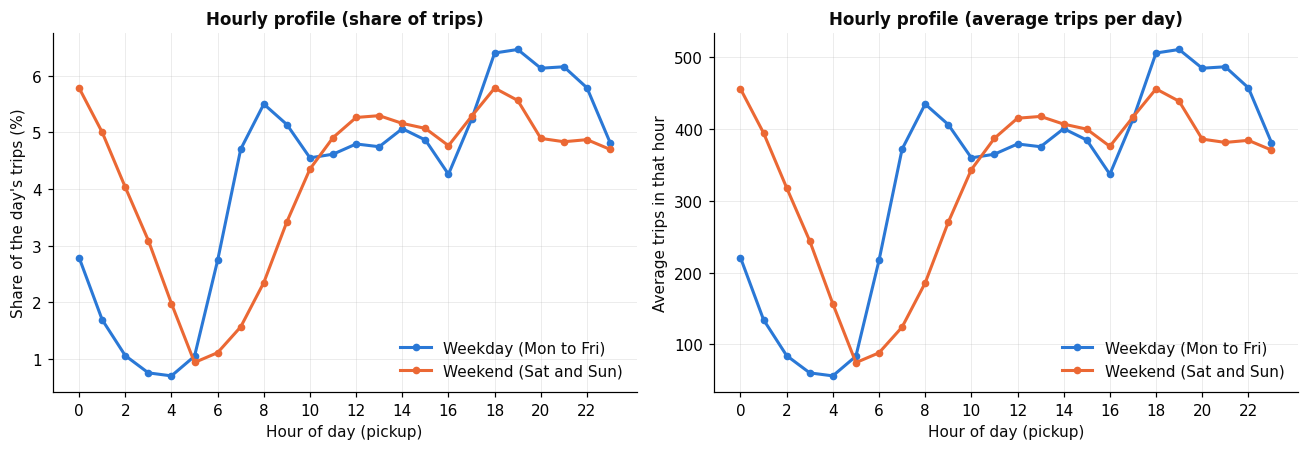

saved q3_3_weekday_vs_weekend_hourly.png


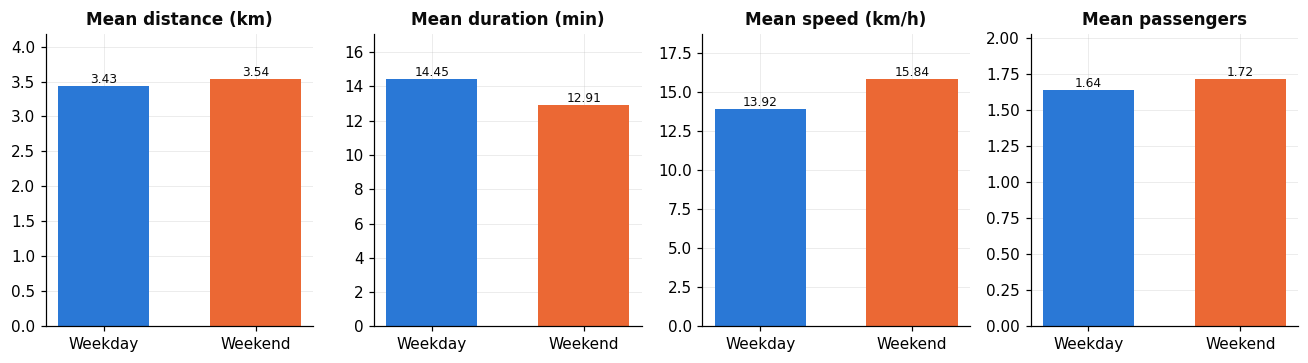

saved q3_3_weekday_weekend_stats.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, data, ylabel, title in [
    (axes[0], profile_share, "Share of the day's trips (%)", "Hourly profile (share of trips)"),
    (axes[1], profile_abs, "Average trips in that hour", "Hourly profile (average trips per day)"),
]:
    ax.plot(data.index, data.Weekday, color=BLUE, lw=2, marker="o", ms=4, label="Weekday (Mon to Fri)")
    ax.plot(data.index, data.Weekend, color=ORANGE, lw=2, marker="o", ms=4, label="Weekend (Sat and Sun)")
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("Hour of day (pickup)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend(frameon=False)
fig.tight_layout()
save(fig, "q3_3_weekday_vs_weekend_hourly.png")

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, col, label in [(axes[0], "mean_distance_km", "Mean distance (km)"),
                       (axes[1], "mean_duration_min", "Mean duration (min)"),
                       (axes[2], "mean_speed_kmh", "Mean speed (km/h)"),
                       (axes[3], "mean_passengers", "Mean passengers")]:
    v = stats.loc[["Weekday", "Weekend"], col]
    ax.bar(v.index, v.values, color=[BLUE, ORANGE], width=0.6)
    for i, x in enumerate(v.values):
        ax.text(i, x, f"{x:.2f}", ha="center", va="bottom", fontsize=8)
    ax.set_title(label)
    ax.set_ylim(0, v.max() * 1.18)
fig.tight_layout()
save(fig, "q3_3_weekday_weekend_stats.png")

## 3.4 Major holidays

The 2016 dates are: Martin Luther King Day (Monday 18 January), Valentine's Day (Sunday 14 February),
St. Patrick's Day (Thursday 17 March), Easter (Sunday 27 March) and Memorial Day (Monday 30 May).
Each holiday is compared with the average of all other days with the same day of the week.
The baseline leaves out the five holidays and 23 and 24 January, when the blizzard "Jonas" shut down the city.

In [16]:
HOLIDAYS = {
    "Martin Luther King Day": pd.Timestamp("2016-01-18"),
    "Valentine's Day": pd.Timestamp("2016-02-14"),
    "St. Patrick's Day": pd.Timestamp("2016-03-17"),
    "Easter": pd.Timestamp("2016-03-27"),
    "Memorial Day": pd.Timestamp("2016-05-30"),
}
BLIZZARD = [pd.Timestamp("2016-01-23"), pd.Timestamp("2016-01-24")]
excluded = set(HOLIDAYS.values()) | set(BLIZZARD)

hourly_date = df.groupby(["date", "hour"]).size().unstack("hour", fill_value=0)
all_dates = hourly_date.index

rows, curves = [], {}
for name, d in HOLIDAYS.items():
    base_dates = [x for x in all_dates if x.dayofweek == d.dayofweek and x not in excluded]
    base_curve = hourly_date.loc[base_dates].mean()
    hol_curve = hourly_date.loc[d]
    curves[name] = (hol_curve, base_curve, base_dates)
    hol_df = df[df.date == d]
    base_df = df[df.date.isin(base_dates)]
    rows.append({
        "holiday": name, "date": d.date(), "weekday": d.day_name(),
        "baseline_days": len(base_dates),
        "trips": int(hol_curve.sum()), "baseline_mean_trips": round(base_curve.sum()),
        "change_%": round((hol_curve.sum() / base_curve.sum() - 1) * 100, 1),
        "peak_hour": int(hol_curve.idxmax()), "baseline_peak_hour": int(base_curve.idxmax()),
        "mean_distance_km": round(hol_df.distance_km.mean(), 2), "baseline_distance_km": round(base_df.distance_km.mean(), 2),
        "mean_speed_kmh": round(hol_df.avg_speed_kmh.mean(), 2), "baseline_speed_kmh": round(base_df.avg_speed_kmh.mean(), 2),
        "share_midnight_to_5am_%": round((hol_df.hour < 5).mean() * 100, 1),
        "baseline_midnight_to_5am_%": round((base_df.hour < 5).mean() * 100, 1),
    })
holiday_table = pd.DataFrame(rows)
display(holiday_table.T)

,0,1,2,3,4
holiday,Martin Luther King Day,Valentine's Day,St. Patrick's Day,Easter,Memorial Day
date,2016-01-18,2016-02-14,2016-03-17,2016-03-27,2016-05-30
weekday,Monday,Sunday,Thursday,Sunday,Monday
baseline_days,24,23,25,23,24
trips,7038,8349,8152,7267,5491
baseline_mean_trips,7183,7547,8299,7547,7183
change_%,-2.0,10.6,-1.8,-3.7,-23.6
peak_hour,18,17,20,0,16
baseline_peak_hour,18,0,21,0,18
mean_distance_km,3.5,3.31,3.53,3.82,4.3


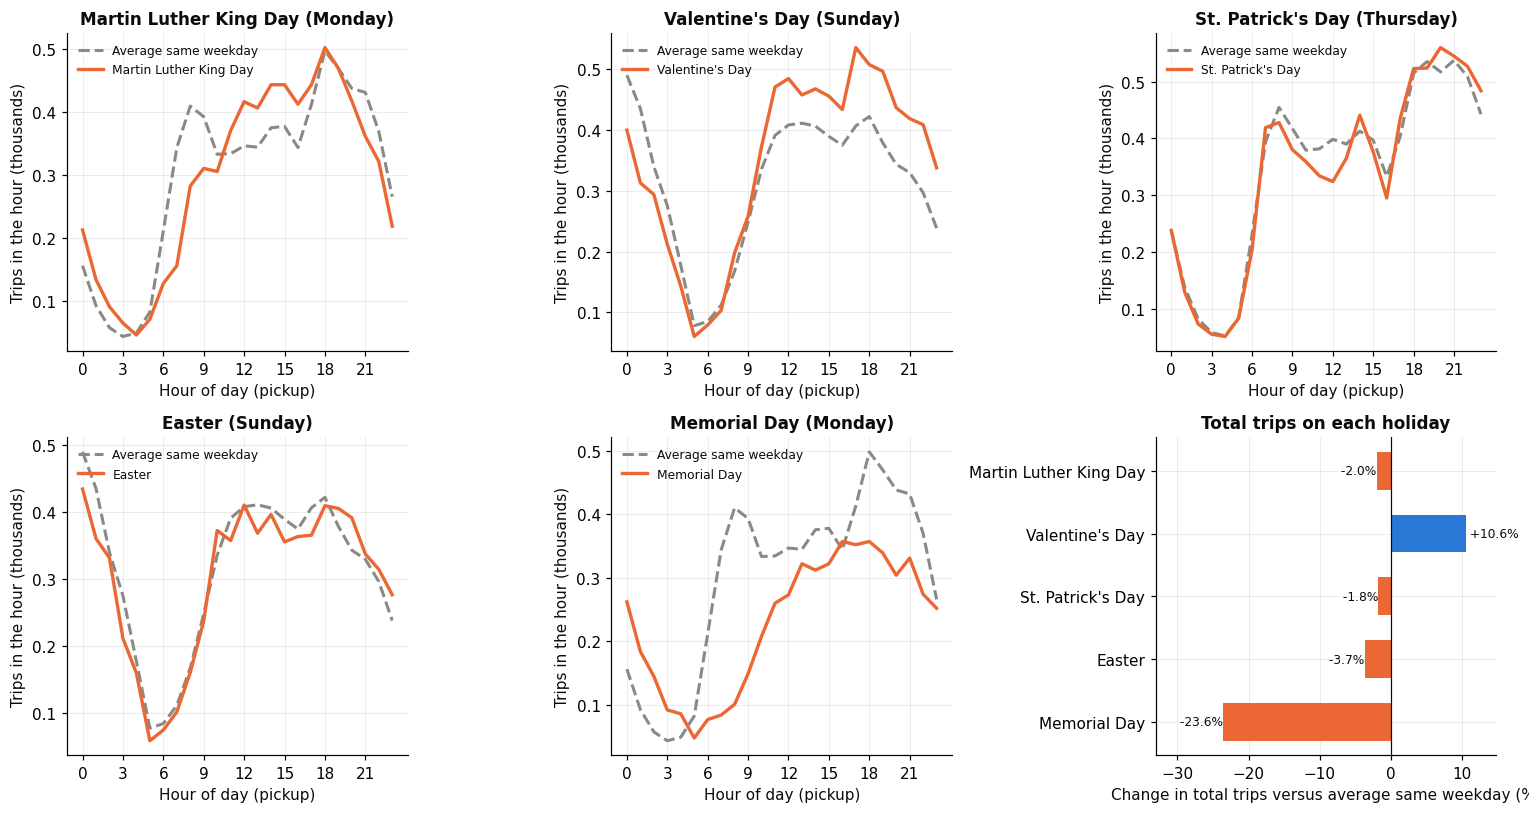

saved q3_4_holidays_hourly.png


In [17]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, (name, (hol, base, _)) in zip(axes.ravel(), curves.items()):
    ax.plot(base.index, base.values / 1000, color=GREY, lw=2, ls="--", label="Average same weekday")
    ax.plot(hol.index, hol.values / 1000, color=ORANGE, lw=2.2, label=name)
    ax.set_title(f"{name} ({HOLIDAYS[name].day_name()})")
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlabel("Hour of day (pickup)")
    ax.set_ylabel("Trips in the hour (thousands)")
    ax.legend(frameon=False, fontsize=8, loc="upper left")
ax = axes[1, 2]
chg = holiday_table.set_index("holiday")["change_%"]
ax.barh(chg.index[::-1], chg.values[::-1], color=[BLUE if v >= 0 else ORANGE for v in chg.values[::-1]], height=0.6)
for i, v in enumerate(chg.values[::-1]):
    ax.text(v, i, f" {v:+.1f}%", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color=INK, lw=0.8)
ax.set_xlabel("Change in total trips versus average same weekday (%)")
ax.set_title("Total trips on each holiday")
ax.set_xlim(min(chg.min() * 1.4, -5), max(chg.max() * 1.4, 5))
fig.tight_layout()
save(fig, "q3_4_holidays_hourly.png")

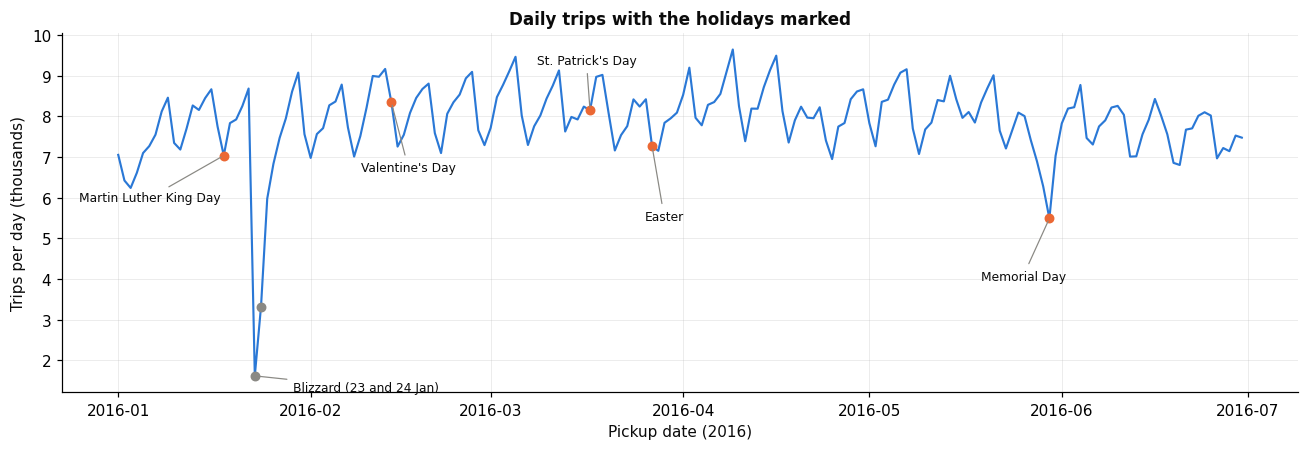

saved q3_4_daily_series.png


In [18]:
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.plot(daily.index, daily.trips / 1000, color=BLUE, lw=1.4)
offsets = {"Martin Luther King Day": (-95, -30), "Valentine's Day": (-20, -45), "St. Patrick's Day": (-35, 30),
           "Easter": (-5, -48), "Memorial Day": (-45, -40)}
for name, d in HOLIDAYS.items():
    y = daily.loc[d, "trips"] / 1000
    ax.scatter([d], [y], color=ORANGE, zorder=3, s=30)
    ax.annotate(name, (d, y), xytext=offsets[name], textcoords="offset points", fontsize=8, color=INK,
                arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))
y = daily.loc[BLIZZARD[0], "trips"] / 1000
ax.scatter(BLIZZARD, daily.loc[BLIZZARD, "trips"] / 1000, color=GREY, zorder=3, s=30)
ax.annotate("Blizzard (23 and 24 Jan)", (BLIZZARD[0], y), xytext=(25, -10), textcoords="offset points", fontsize=8,
            arrowprops=dict(arrowstyle="-", color=GREY, lw=0.8))
ax.set_ylabel("Trips per day (thousands)")
ax.set_xlabel("Pickup date (2016)")
ax.set_title("Daily trips with the holidays marked")
fig.tight_layout()
save(fig, "q3_4_daily_series.png")

## 3.5 Average speed through the day

In [19]:
speed_hour = df.groupby("hour").avg_speed_kmh.agg(["mean", "median"]).round(2)
speed_type = df.groupby(["hour", "day_type"]).avg_speed_kmh.mean().unstack("day_type").round(2)
speed_dh = df.groupby(["day_of_week", "hour"]).avg_speed_kmh.mean().unstack("hour").reindex(DAYS)
display(pd.concat([speed_hour, speed_type], axis=1, keys=["overall", "mean by day type"]).T)
print("Fastest hour overall (mean):", speed_hour["mean"].idxmax(), speed_hour["mean"].max())
print("Slowest hour overall (mean):", speed_hour["mean"].idxmin(), speed_hour["mean"].min())
print("Fastest hour weekday:", speed_type.Weekday.idxmax(), " weekend:", speed_type.Weekend.idxmax())
print("Slowest hour weekday:", speed_type.Weekday.idxmin(), " weekend:", speed_type.Weekend.idxmin())

hour                         0      1      2      3      4      5      6   \
overall          mean     17.76  18.54  18.96  20.04  22.32  24.56  20.58   
                 median   16.09  17.04  17.59  18.58  20.63  22.83  19.01   
mean by day type Weekday  19.45  20.52  20.82  21.79  24.23  24.54  19.86   
                 Weekend  15.71  16.85  17.73  18.96  20.61  24.61  25.03   

hour                         7      8      9   ...     14     15     16  \
overall          mean     15.83  13.03  12.67  ...  12.26  12.13  12.61   
                 median   14.33  11.43  10.99  ...  10.93  10.96  11.52   
mean by day type Weekday  14.95  11.89  11.27  ...  11.56  11.40  12.01   
                 Weekend  22.49  19.69  17.93  ...  13.98  13.89  13.96   

hour                         17     18     19     20     21     22     23  
overall          mean     12.54  12.58  13.64  15.20  15.84  16.07  16.95  
                 median   11.52  11.47  12.28  13.71  14.34  14.60  15.31  
mean by day type Weekday  11.95  12.19  13.58  15.27  15.87  16.10  17.08  
                 Weekend  13.99  13.68  13.82  14.98  15.77  16.00  16.61  

[4 rows x 24 columns]

Fastest hour overall (mean): 5 24.56
Slowest hour overall (mean): 15 12.13
Fastest hour weekday: 5  weekend: 6
Slowest hour weekday: 11  weekend: 18


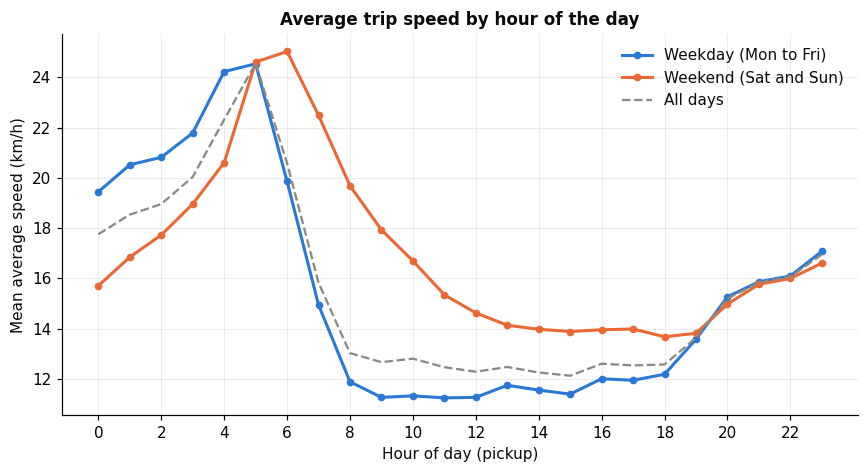

saved q3_5_speed_by_hour.png


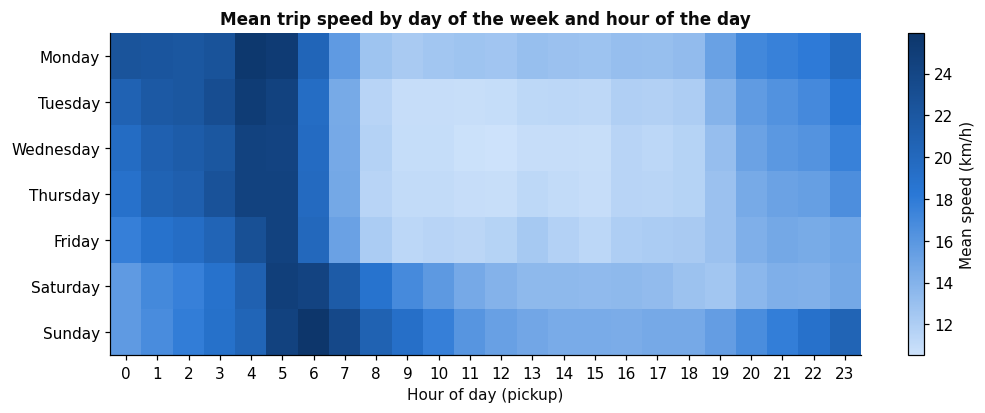

saved q3_5_speed_heatmap.png


In [20]:
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(speed_type.index, speed_type.Weekday, color=BLUE, lw=2, marker="o", ms=4, label="Weekday (Mon to Fri)")
ax.plot(speed_type.index, speed_type.Weekend, color=ORANGE, lw=2, marker="o", ms=4, label="Weekend (Sat and Sun)")
ax.plot(speed_hour.index, speed_hour["mean"], color=GREY, lw=1.5, ls="--", label="All days")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day (pickup)")
ax.set_ylabel("Mean average speed (km/h)")
ax.set_title("Average trip speed by hour of the day")
ax.legend(frameon=False)
fig.tight_layout()
save(fig, "q3_5_speed_by_hour.png")

fig, ax = plt.subplots(figsize=(11, 3.8))
im = ax.imshow(speed_dh.values, aspect="auto", cmap=SEQ)
ax.set_xticks(range(24))
ax.set_yticks(range(7))
ax.set_yticklabels(DAYS)
ax.set_xlabel("Hour of day (pickup)")
ax.grid(False)
cb = fig.colorbar(im, ax=ax)
cb.set_label("Mean speed (km/h)")
ax.set_title("Mean trip speed by day of the week and hour of the day")
save(fig, "q3_5_speed_heatmap.png")

In [21]:
import glob
print("Figures saved in this folder:")
for f in sorted(glob.glob("q*.png")):
    print(" ", f)

Figures saved in this folder:
  q1_outliers_before_after.png
  q1_pickup_coordinates_before_after.png
  q2_feature_distributions.png
  q3_1_trips_by_weekday.png
  q3_2_heatmap_day_hour.png
  q3_2_hourly_by_day.png
  q3_3_weekday_vs_weekend_hourly.png
  q3_3_weekday_weekend_stats.png
  q3_4_daily_series.png
  q3_4_holidays_hourly.png
  q3_5_speed_by_hour.png
  q3_5_speed_heatmap.png
